In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

data_path = Path("StudentPerformanceFactors.csv")

output_dir = Path("outputs")
chart_dir = output_dir / "charts"
chart_dir.mkdir(parents=True, exist_ok=True)

if not data_path.exists():
    raise FileNotFoundError(
        "Download the Kaggle CSV and save it as "
        "StudentPerformanceFactors.csv"
    )

df = pd.read_csv(data_path)

print("Dataset size:", df.shape)
display(df.head())

Matplotlib is building the font cache; this may take a moment.


Dataset size: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [2]:
columns = [
    "Hours_Studied",
    "Attendance",
    "Sleep_Hours",
    "Previous_Scores",
    "Tutoring_Sessions",
    "Exam_Score",
]

missing = [col for col in columns if col not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

print("Duplicate rows:", df.duplicated().sum())
print("Missing values:")
display(df[columns].isna().sum())

df = df.drop_duplicates().copy()

for col in columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=columns)

summary = df[columns].describe().round(2)
display(summary)

summary.to_csv(output_dir / "statistical_summary.csv")

df[columns].to_csv(
    output_dir / "spreadsheet_data.csv",
    index=False
)

Duplicate rows: 0
Missing values:


Hours_Studied        0
Attendance           0
Sleep_Hours          0
Previous_Scores      0
Tutoring_Sessions    0
Exam_Score           0
dtype: int64

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Exam_Score
count,6607.00,6607.00,6607.00,6607.00,6607.00,6607.00
mean,19.98,79.98,7.03,75.07,1.49,67.24
std,5.99,11.55,1.47,14.40,1.23,3.89
min,1.00,60.00,4.00,50.00,0.00,55.00
25%,16.00,70.00,6.00,63.00,1.00,65.00
50%,20.00,80.00,7.00,75.00,1.00,67.00
75%,24.00,90.00,8.00,88.00,2.00,69.00
max,44.00,100.00,10.00,100.00,8.00,101.00


In [3]:
correlations = df[columns].corr().round(3)

display(correlations)

correlations.to_csv(output_dir / "correlation_analysis.csv")

print("Correlations with exam score:")
display(
    correlations["Exam_Score"]
    .drop("Exam_Score")
    .sort_values(ascending=False)
)

# Compare the full dataset with a random 20% sample
sample = df.sample(frac=0.20, random_state=42)

comparison = pd.DataFrame({
    "Measure": ["Exam score", "Attendance", "Study hours"],
    "Full dataset mean": [
        df["Exam_Score"].mean(),
        df["Attendance"].mean(),
        df["Hours_Studied"].mean(),
    ],
    "Sample mean": [
        sample["Exam_Score"].mean(),
        sample["Attendance"].mean(),
        sample["Hours_Studied"].mean(),
    ],
})

comparison["Difference"] = (
    comparison["Full dataset mean"] - comparison["Sample mean"]
).abs().round(2)

display(comparison.round(2))

comparison.to_csv(
    output_dir / "spreadsheet_crosscheck.csv",
    index=False
)

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Exam_Score
Hours_Studied,1.000,-0.010,0.011,0.025,-0.014,0.445
Attendance,-0.010,1.000,-0.016,-0.020,0.014,0.581
Sleep_Hours,0.011,-0.016,1.000,-0.022,-0.012,-0.017
Previous_Scores,0.025,-0.020,-0.022,1.000,-0.013,0.175
Tutoring_Sessions,-0.014,0.014,-0.012,-0.013,1.000,0.157
Exam_Score,0.445,0.581,-0.017,0.175,0.157,1.000


Correlations with exam score:


Attendance           0.581
Hours_Studied        0.445
Previous_Scores      0.175
Tutoring_Sessions    0.157
Sleep_Hours         -0.017
Name: Exam_Score, dtype: float64

,Measure,Full dataset mean,Sample mean,Difference
0,Exam score,67.24,67.31,0.08
1,Attendance,79.98,80.39,0.41
2,Study hours,19.98,20.01,0.03


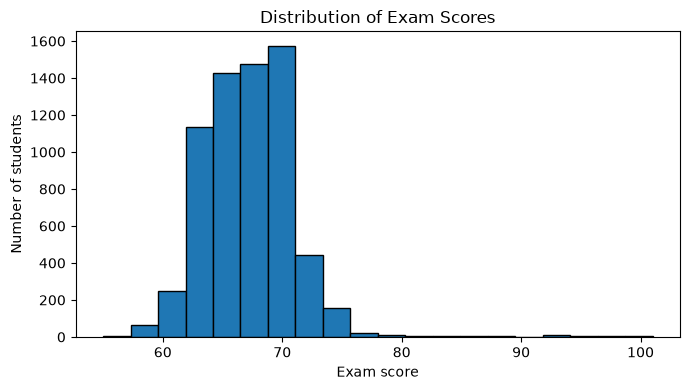

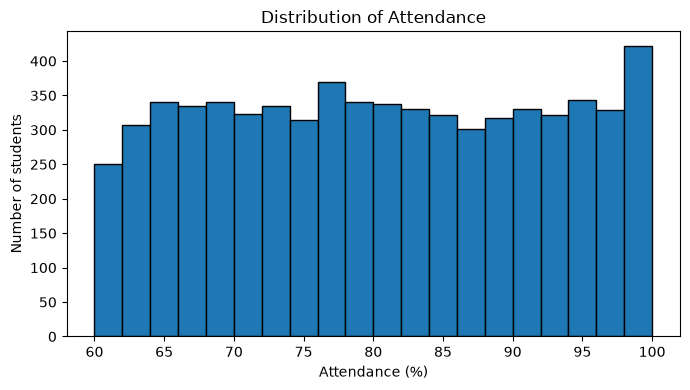

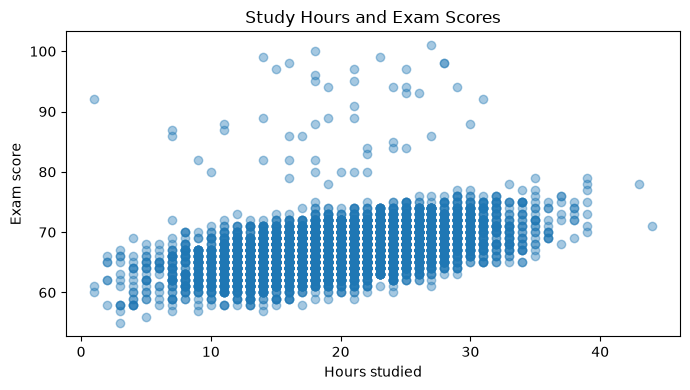

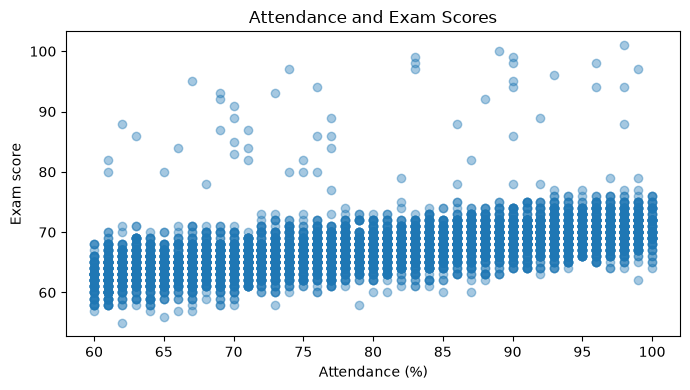

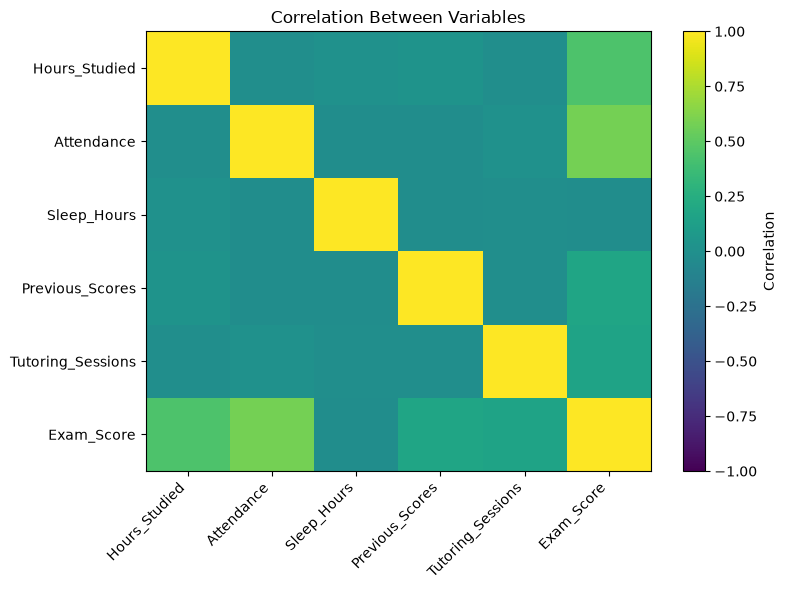

In [4]:
# Chart 1: Exam score distribution
plt.figure(figsize=(7, 4))
plt.hist(df["Exam_Score"], bins=20, edgecolor="black")
plt.title("Distribution of Exam Scores")
plt.xlabel("Exam score")
plt.ylabel("Number of students")
plt.tight_layout()
plt.savefig(chart_dir / "exam_scores.png")
plt.show()


# Chart 2: Attendance distribution
plt.figure(figsize=(7, 4))
plt.hist(df["Attendance"], bins=20, edgecolor="black")
plt.title("Distribution of Attendance")
plt.xlabel("Attendance (%)")
plt.ylabel("Number of students")
plt.tight_layout()
plt.savefig(chart_dir / "attendance.png")
plt.show()


# Chart 3: Study hours versus exam score
plt.figure(figsize=(7, 4))
plt.scatter(df["Hours_Studied"], df["Exam_Score"], alpha=0.4)
plt.title("Study Hours and Exam Scores")
plt.xlabel("Hours studied")
plt.ylabel("Exam score")
plt.tight_layout()
plt.savefig(chart_dir / "study_hours.png")
plt.show()


# Chart 4: Attendance versus exam score
plt.figure(figsize=(7, 4))
plt.scatter(df["Attendance"], df["Exam_Score"], alpha=0.4)
plt.title("Attendance and Exam Scores")
plt.xlabel("Attendance (%)")
plt.ylabel("Exam score")
plt.tight_layout()
plt.savefig(chart_dir / "attendance_scores.png")
plt.show()


# Chart 5: Correlation heatmap
plt.figure(figsize=(8, 6))
plt.imshow(correlations, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(columns)),
    columns,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(columns)), columns)

plt.title("Correlation Between Variables")
plt.tight_layout()
plt.savefig(chart_dir / "correlation_heatmap.png")
plt.show()

In [5]:
study_low = df["Hours_Studied"].quantile(0.25)
study_high = df["Hours_Studied"].quantile(0.75)

attendance_low = df["Attendance"].quantile(0.25)
attendance_high = df["Attendance"].quantile(0.75)

low_study_scores = df.loc[
    df["Hours_Studied"] <= study_low, "Exam_Score"
]
high_study_scores = df.loc[
    df["Hours_Studied"] >= study_high, "Exam_Score"
]

low_attendance_scores = df.loc[
    df["Attendance"] <= attendance_low, "Exam_Score"
]
high_attendance_scores = df.loc[
    df["Attendance"] >= attendance_high, "Exam_Score"
]

score_correlations = (
    correlations["Exam_Score"]
    .drop("Exam_Score")
)

strongest = score_correlations.abs().idxmax()

insights = [
    f"1. The dataset contains {len(df)} usable records. "
    f"The average exam score is {df['Exam_Score'].mean():.2f}, "
    f"and the median is {df['Exam_Score'].median():.2f}.",

    f"2. Average attendance is {df['Attendance'].mean():.2f}%. "
    "The attendance histogram shows how attendance values are distributed.",

    f"3. Among the selected variables, {strongest} has the strongest "
    f"absolute correlation with exam score "
    f"(r = {score_correlations[strongest]:.2f}).",

    f"4. Students in the lowest attendance quartile averaged "
    f"{low_attendance_scores.mean():.2f}, compared with "
    f"{high_attendance_scores.mean():.2f} in the highest attendance quartile.",

    f"5. Students in the lowest study-hours quartile averaged "
    f"{low_study_scores.mean():.2f}, compared with "
    f"{high_study_scores.mean():.2f} in the highest study-hours quartile.",
]

for insight in insights:
    print(insight)

print(
    "\nImportant: Correlation and group differences do not prove "
    "that attendance or studying caused the score differences. "
    "Other factors may influence results."
)

(output_dir / "five_insights.md").write_text(
    "# Five Written Insights\n\n"
    + "\n\n".join(insights)
    + "\n\n## Limitation\n\n"
    "These findings describe the selected dataset. "
    "Correlation does not prove causation.\n",
    encoding="utf-8"
)

print(f"\nOutputs saved to: {output_dir.resolve()}")

1. The dataset contains 6607 usable records. The average exam score is 67.24, and the median is 67.00.
2. Average attendance is 79.98%. The attendance histogram shows how attendance values are distributed.
3. Among the selected variables, Attendance has the strongest absolute correlation with exam score (r = 0.58).
4. Students in the lowest attendance quartile averaged 64.33, compared with 70.14 in the highest attendance quartile.
5. Students in the lowest study-hours quartile averaged 65.15, compared with 69.37 in the highest study-hours quartile.

Important: Correlation and group differences do not prove that attendance or studying caused the score differences. Other factors may influence results.

Outputs saved to: /Users/ahmib/python/student_analysis/outputs
